# Tutorial 5 — Time–cure superposition

During curing, crosslinking progressively lengthens the relaxation times of a
material until it gels. If the shape of the relaxation spectrum is preserved
while its characteristic time grows, spectra measured at successive cure times
$t_\mathrm{c}$ superpose after a horizontal shift $a_t$ along the frequency
axis,

$$
G^{*}(\omega; t_\mathrm{c}) = G^{*}(a_t\,\omega; t_\mathrm{ref}),
$$

the time–cure superposition (tCS) analogue of time–temperature superposition
([Tutorial 4](./4_time%20temperature%20superposition.ipynb)). The
evolution of $a_t$ with $t_\mathrm{c}$ tracks cure kinetics, and at the gel
point the spectrum becomes a power law, $G' \sim G'' \sim \omega^{n}$ (Chambon
and Winter, 1987).

Conventional frequency sweeps are too slow for a sample that changes during
the measurement. OWChirp records a full spectrum in a few seconds, so a
sequence of chirps gives quasi-static snapshots of the curing material
(Perego et al., 2025). The shifts are estimated with the automated method of
Lennon et al. (2023), using the cure time as state variable.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.automated_mastercurve import AutomatedMasterCurve
from hermes_rheo.transforms.owchirp_analysis import OWChirpAnalysis
from hermes_rheo.visualization import axis_label, plot_master_curve, use_science_style

use_science_style()
warnings.filterwarnings("ignore")  # scikit-learn / SciPy convergence notices
DATA = Path("tutorial_data")

## Master curve

The pipeline matches Tutorial 4 with time as the state variable. Each chirp
is assigned the time of its first point (`state_mode="first point"`), since
averaging over a short chirp adds no information. The superposition starts
from the last, most cured spectrum (`reverse_data=True`), whose high modulus
gives the best-defined Gaussian-process fit. `change_ref` then moves the
reference to the first chirp, so that $a_t = 1$ at the start of the cure.

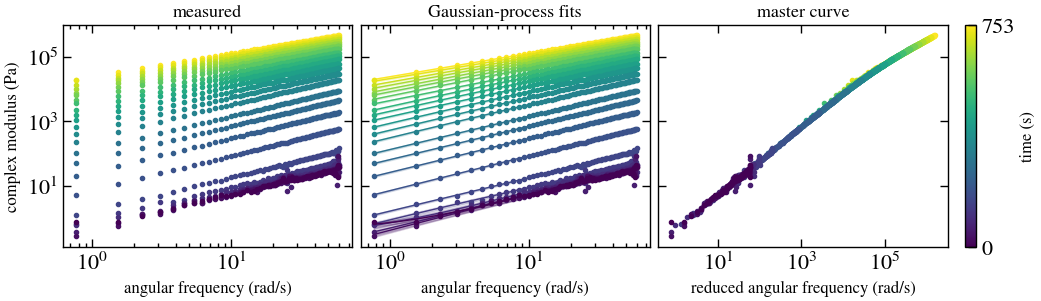

In [2]:
experiment = read_file(DATA / "aresg2_trios_owchirp_time_sweep.txt",
                       file_reader=TriosRheoReader, create_composite_datasets=True)

mastercurve = (OWChirpAnalysis() + AutomatedMasterCurve(
    state="time", state_mode="first point",
    x="angular frequency", y="complex modulus",
    vertical_shift=False, reverse_data=True,
))(experiment)
mastercurve.change_ref(mastercurve.states[-1])

fig, axes = plot_master_curve(mastercurve, cmap="viridis", lowest_on_top=False)

The panels show the measured spectra, their Gaussian-process fits and the
master curve; the colour bar gives the cure time. The shift factors are stored
in `mastercurve.datasets[1]` (cure time against $a_t$), with their
uncertainties in `mastercurve.details["horizontal_shift_uncertainties"]`.

## Horizontal shift factors

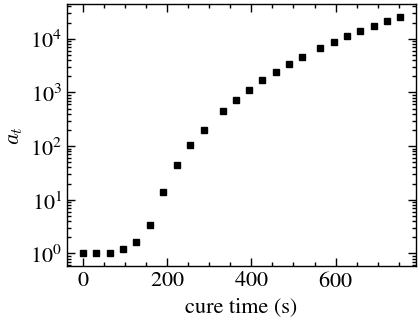

In [3]:
shifts = mastercurve.datasets[1]
a_t_err = mastercurve.details["horizontal_shift_uncertainties"]

fig, ax = plt.subplots(figsize=(4.5, 3.4))
ax.errorbar(shifts.x_values, shifts.y_values, yerr=a_t_err, fmt="s", ms=4,
            color="black", capsize=2)
ax.set_yscale("log")
ax.set(xlabel=axis_label(shifts, shifts.x_name, text="cure time"),
       ylabel=axis_label(shifts, shifts.y_name, text="$a_t$"));

The OWChirp data were decimated by a factor of 4 (every 4th point kept) to reduce file size; the full-resolution files are available on request from Alessandro Perego (aperego@mmm.com).

## References

- Chambon, F. and Winter, H. H., *Linear Viscoelasticity at the Gel Point of a
  Crosslinking PDMS with Imbalanced Stoichiometry*, *Journal of Rheology*
  **31**, 683–697 (1987). DOI: [10.1122/1.549955](https://doi.org/10.1122/1.549955).
- Lennon, K. R., McKinley, G. H. and Swan, J. W., *A data-driven method for
  automated data superposition with applications in soft matter science*,
  *Data-Centric Engineering* **4**, e13 (2023).
  DOI: [10.1017/dce.2023.3](https://doi.org/10.1017/dce.2023.3).
- Perego, A., Vadillo, D. C., Mills, M. J. L., Das, M. and McKinley, G. H.,
  *Evaluation of Optimally Windowed Chirp Signals in Industrial Rheological
  Measurements: Method Development and Data Processing*, *Rheologica Acta*
  **64**, 391–406 (2025).
  DOI: [10.1007/s00397-025-01511-0](https://doi.org/10.1007/s00397-025-01511-0).